# Qwen2.5-0.5B gọi công cụ: cách B (theo TinyAgent)

**Mục tiêu** giống cách A: dạy Qwen2.5-0.5B chọn đúng 1 trong 11 công cụ (kèm tham số) hoặc không chọn công cụ nào.
Khác ở **cách dạy**: notebook này làm theo công thức của bài *TinyAgent: Function Calling at the Edge* (EMNLP 2024),
để so sánh với cách A trên cùng bộ đo.

**Công thức của bài và phần mình làm**

| Ý của bài | Bài làm | Bản B làm | Khác biệt |
|---|---|---|---|
| Dữ liệu do LLM lớn viết | GPT-4-Turbo, 80 nghìn mẫu | Phi-4-mini (3.8B, chạy máy bạn), khoảng 1700 câu | teacher nhỏ hơn, ít mẫu hơn |
| Kiểm tra dữ liệu | kiểm tra kế hoạch có khả thi | luật từ khoá: đúng số, đúng chủ đề, không lẫn sang công cụ khác | luật khác vì bài toán khác |
| Mẫu phủ định | prompt có thêm hàm không liên quan | giống: công cụ đúng + vài công cụ không liên quan | 30% mẫu vẫn giữ đủ 11 công cụ |
| Dạy bằng LoRA | 3 vòng, lr 7e-5 | giống (r=16, alpha=32 vì bài không nêu) | |
| Bộ chọn công cụ (Tool RAG) | DeBERTa-v3-small, ngưỡng 0.5 | giống, thêm luôn lấy ít nhất 3 công cụ | tránh thiếu công cụ đúng |
| Nén 4-bit nhóm 32 kèm QAT | có | Q4_0 (4-bit, nhóm 32) **nhưng không QAT** | nén sau huấn luyện |

**Không làm:** học tăng cường (GRPO) và quy trình Plan-Retrieve-Select của bài arXiv 2610.31483. Chúng dành cho bài toán nhiều bước
trên kho công cụ rất lớn, quá nặng và không cần cho 11 công cụ.

**Điều giữ giống cách A để so sánh công bằng:** cùng model gốc, cùng bộ test 156 câu và bộ giữ riêng (sinh cùng seed),
cùng nhiễu giọng nói cho một nửa số câu, cùng prompt đặt phần cố định lên đầu, cùng JSON schema ép đầu ra.

**Cách đo công bằng với bộ chọn công cụ:** RAM và thời gian của bộ chọn (DeBERTa) được cộng vào kết quả, vì nó cũng chạy trên UNO Q.

**Cần có trong thư mục làm việc:** các file của cách A (`tool_cases.py`, `slm_tools.py`, `model_catalog.py`, `make_train.py`, `train_sft.py`,
`lora_train.py`, `gguf_tools.py`, `eval_tools.py`) cùng `teacher_data.py` và `tool_rag.py`; thư mục `llama.cpp`.

**Thời gian ước tính:** teacher viết câu khoảng 15-25 phút, bộ chọn công cụ vài phút, dạy 15-25 phút, đo 4 cấu hình khoảng 30 phút.

## 1. Chuẩn bị

`sentencepiece` và `protobuf` cần cho bộ tách từ của DeBERTa.

In [1]:
%pip install -q peft pandas matplotlib sentencepiece protobuf

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, sys
from pathlib import Path
if Path.cwd().name == 'finetuning':
    os.chdir('..')
for _p in (Path.cwd(), Path.cwd() / 'finetuning'):
    if str(_p) not in sys.path:
        sys.path.insert(0, str(_p))

import json
import random
import time
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import psutil
import torch

import eval_tools_B as E
import gguf_tools
import lora_train
import make_train
import model_catalog as catalog
import slm_tools
import teacher_data as D
import tool_cases as T
import tool_rag as R

### Cấu hình

- `TEACHER`: model viết câu nói. Dùng Phi-4-mini vì máy bạn đã có file GGUF (từ lần đo benchmark).
- `N_PER_TOOL`, `N_OOS`: số câu hợp lệ cần cho mỗi công cụ, và cho nhóm câu ngoài phạm vi.
- `LORA`: đúng theo bài (3 vòng, lr 7e-5). Bài không nêu r và alpha nên mình dùng giá trị phổ biến (16 và 32).
- `RAG`: `threshold` là ngưỡng xác suất để đưa một công cụ vào prompt, `min_tools` là số công cụ tối thiểu luôn lấy.
- `QUANTS`: Q4_0 là 4-bit chia nhóm 32 trọng số, giống cấu hình của bài (nhưng bài có thêm QAT).

In [3]:
BASE_NAME = "Qwen2.5-0.5B-Instruct"
HF_REPO = "Qwen/Qwen2.5-0.5B-Instruct"
LLAMA_DIR = "./llama.cpp"

TEACHER = ("Phi-4-mini-instruct", "Phi-4-mini", "Q8_0")      # (tên trong catalog, một phần tên để tìm cấu hình, mức nén)
N_PER_TOOL, N_OOS = 130, 260

RUN_DIR = Path("runs/qwen05_B")
TEACHER_FILE = RUN_DIR / "teacher_queries.jsonl"
TRAIN_FILE = RUN_DIR / "train_teacher.jsonl"
RETRIEVER_DIR = RUN_DIR / "retriever"
MERGED_DIR = RUN_DIR / "merged"
GGUF_DIR = RUN_DIR / "gguf"

LORA = dict(r=16, alpha=32, dropout=0.05, lr=7e-5, epochs=3, bs=1, accum=16)
RAG = dict(threshold=0.5, min_tools=3)
QUANTS = ["Q8_0", "Q4_0"]
RETRAIN = False

RUN_DIR.mkdir(parents=True, exist_ok=True)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "không có (sẽ rất chậm)")

GPU: NVIDIA GeForce RTX 4070


### Bộ đo (giống cách A)

Bộ giữ riêng được sinh bằng cùng một seed như cách A nên hai bên đo trên **đúng cùng các câu**.
`blocked` là tập mọi câu đo; câu do teacher viết mà trùng với chúng sẽ bị loại để không rò rỉ.

In [4]:
_, held = make_train.build_dataset()
EVAL_SETS = {"156": E.test156(), "lạ": held}
blocked = {make_train.normalize(c["context"]["user_prompt"]) for cases in EVAL_SETS.values() for c in cases}
print({name: len(cases) for name, cases in EVAL_SETS.items()}, "| số câu bị chặn:", len(blocked))

{'156': 156, 'lạ': 156} | số câu bị chặn: 185


## 2. Teacher viết câu nói

Với cách A, câu nói do chương trình dựng từ mẫu nên cách diễn đạt bị giới hạn theo những gì mình nghĩ ra. Ở đây một **LLM lớn hơn**
(teacher) viết câu nói, nên đa dạng hơn rất nhiều. Cách làm:

1. Chương trình chọn trước công cụ và tham số đúng, ví dụ `request_set_speed` với `35 rpm`. **Nhãn luôn đúng.**
2. Chương trình mô tả ý định bằng lời thường ("change the speed of the running belt to 35 rpm") và nhờ teacher viết 6 cách nói khác nhau.
3. Mỗi câu phải qua **bước kiểm tra**: có nói đúng số 35, có từ chỉ tốc độ, không nhầm sang "restart", không lộ tên công cụ...
   Câu trùng, hoặc trùng với bộ đo, bị loại.
4. Lặp lại cho đến khi mỗi công cụ đủ số câu. File `teacher_queries.jsonl` lưu từng câu được nhận nên **bị dừng giữa chừng thì chạy lại sẽ làm tiếp**.

Teacher chạy bằng GPU (`gpu_layers=99`).

In [5]:
teacher_base, teacher_find, teacher_quant = TEACHER
quota = lambda tool: N_OOS if tool is None else N_PER_TOOL
have = Counter(a["tool"] for a in D.load_accepted(TEACHER_FILE))
stats = Counter()

if any(have[tool] < quota(tool) for tool in D.ALL_TOOLS + [None]):          # chỉ bật teacher nếu còn thiếu câu
    catalog.ensure_gguf(teacher_base, teacher_quant, llama_cpp_dir=LLAMA_DIR)
    teacher_cfg = E.find_cfg(teacher_find, teacher_quant)

    with slm_tools.server(teacher_cfg, n_ctx=2048, gpu_layers=99) as teacher_server:
        chat = D.make_chat(teacher_server.url)

        print("--- Ví dụ: teacher viết gì cho ý 'đổi tốc độ sang 35 rpm' ---")
        print(chat(D.teacher_messages("request_set_speed", {"target_speed_rpm": 35}, 6), seed=1))

        stats = D.generate(chat, TEACHER_FILE, N_PER_TOOL, N_OOS, blocked)
else:
    print("Đã có đủ câu từ lần chạy trước.")

Đã có đủ câu từ lần chạy trước.


### Teacher viết bao nhiêu và bao nhiêu câu được nhận

Tỉ lệ nhận thấp ở một công cụ nghĩa là teacher hay viết lệch ý ở công cụ đó (ví dụ nhầm "lịch sử" với "đọc ngay").
Nếu tỉ lệ quá thấp (dưới 30%) thì nên xem lại luật kiểm tra trong `teacher_data.py`. Bảng chỉ hiện khi vừa chạy sinh câu.

In [6]:
if stats:
    tools = D.ALL_TOOLS + [None]
    table_stats = pd.DataFrame({"teacher viết": [stats[(t, "viết")] for t in tools],
                                "được nhận": [stats[(t, "nhận")] for t in tools]},
                               index=[t or "(ngoài phạm vi)" for t in tools])
    table_stats["tỉ lệ nhận"] = (table_stats["được nhận"] / table_stats["teacher viết"].clip(lower=1)).round(2)
    display(table_stats)
else:
    print("Đã có đủ câu từ lần chạy trước, không cần hỏi teacher thêm.")

Đã có đủ câu từ lần chạy trước, không cần hỏi teacher thêm.


Một vài câu được nhận để xem bằng mắt:

In [7]:
accepted = D.load_accepted(TEACHER_FILE)
random.seed(5)
pd.DataFrame([{"câu nói": a["text"], "công cụ đúng": a["tool"] or "(ngoài phạm vi)", "tham số": a["args"]}
              for a in random.sample(accepted, 12)])

,câu nói,công cụ đúng,tham số
0,Remind me to call John tomorrow at 3 PM.,(ngoài phạm vi),{}
1,Throughput count for the shift?,get_production_stats,{'period': 'this_shift'}
2,Could you tell me why the conveyor stopped las...,get_last_stop_reason,{}
3,Shut down conveyor instantly,request_line_stop,{}
4,How many items did we produce in the past hour?,get_production_stats,{'period': 'last_hour'}
5,"Last time, the conveyor stopped, what's the ca...",get_last_stop_reason,{}
6,"Alarm deactivated, jam fixed.",acknowledge_alarm,{}
7,How many units were produced in the previous h...,get_production_stats,{'period': 'last_hour'}
8,"Motor's overheating, sound the alarm.",trigger_audio_alarm,{'alarm_code': 'ALERT_OVERTEMP'}
9,Turn on the living room lights.,(ngoài phạm vi),{}


## 3. Dữ liệu huấn luyện với mẫu phủ định

Câu của teacher được thêm trạng thái máy và nhiễu giọng nói (như cách A), rồi ghép thành prompt. Điểm khác cách A là **tập công cụ
trong prompt thay đổi**: công cụ đúng cộng vài công cụ không liên quan ("mẫu phủ định"). Nhờ đó model học cách bỏ qua công cụ thừa,
và lúc chạy thật prompt chỉ cần chứa những công cụ mà bộ chọn công cụ trả về. 30% mẫu vẫn giữ đủ 11 công cụ để model dùng tốt khi không có bộ chọn.

In [8]:
cases = D.to_cases(accepted)
rows = D.build_training_rows(cases)

with open(TRAIN_FILE, "w", encoding="utf-8") as f:
    for row in rows:
        f.write(json.dumps(row, ensure_ascii=False) + "\n")

full_chars = len(make_train.messages_cached(cases[0], T.NAMES)[0]["content"])
mean_chars = sum(len(r["messages"][0]["content"]) for r in rows) / len(rows)
print(f"{len(rows)} mẫu huấn luyện")
print(f"Phần cố định của prompt: {full_chars} ký tự với 11 công cụ, trung bình {mean_chars:.0f} ký tự trong dữ liệu này")
pd.Series(Counter(r["n_tools"] for r in rows)).sort_index().rename("số mẫu").to_frame().T.rename_axis("số công cụ trong prompt", axis=1)

1690 mẫu huấn luyện
Phần cố định của prompt: 3592 ký tự với 11 công cụ, trung bình 2232 ký tự trong dữ liệu này


số công cụ trong prompt,2,3,4,5,6,7,11
số mẫu,193,234,254,234,222,42,511


## 4. Bộ chọn công cụ (Tool RAG)

Một model phân loại nhỏ (**DeBERTa-v3-small**) đọc câu nói và cho mỗi công cụ một xác suất "liên quan". Công cụ nào vượt ngưỡng 0.5
(và luôn lấy ít nhất 3 công cụ cao nhất) được đưa vào prompt của Qwen. Prompt ngắn hơn thì Qwen đọc nhanh hơn.

Chỉ số quan trọng nhất là **recall**: tỉ lệ câu mà công cụ đúng nằm trong tập được chọn. Nếu bộ chọn bỏ sót công cụ đúng thì
Qwen **không thể** chọn đúng nữa (và schema cũng không cho phép). `avg_tools` là số công cụ trung bình trong prompt.

In [9]:
order = list(range(len(cases)))
random.Random(0).shuffle(order)
cut = int(0.9 * len(order))
fit_cases = [cases[i] for i in order[:cut]]
val_cases = [cases[i] for i in order[cut:]]
prompt_of = lambda case: case["context"]["user_prompt"]

if RETRAIN or not (RETRIEVER_DIR / "head.pt").exists():
    retriever = R.ToolRetriever()
    retriever.fit([prompt_of(c) for c in fit_cases], [c["tool"] for c in fit_cases])
    retriever.save(RETRIEVER_DIR)
else:
    retriever = R.ToolRetriever.load(RETRIEVER_DIR)
    print("Đã có bộ chọn công cụ ở", RETRIEVER_DIR)

select_for = lambda case: retriever.select([prompt_of(case)], **RAG)[0]       # công cụ được chọn cho một câu

report = {name: R.retrieval_report(retriever.select([prompt_of(c) for c in cs], **RAG), cs)
          for name, cs in {"teacher (10% giữ lại)": val_cases, "bộ 156 câu": EVAL_SETS["156"], "bộ giữ riêng": EVAL_SETS["lạ"]}.items()}
pd.DataFrame(report).T

c:\Users\Minor\Downloads\slm\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
The tokenizer you are loading from 'runs\qwen05_B\retriever\encoder' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


Đã có bộ chọn công cụ ở runs\qwen05_B\retriever


,recall,avg_tools
teacher (10% giữ lại),0.994,3.0
bộ 156 câu,1.000,3.0
bộ giữ riêng,0.981,3.0


Hai bộ đo (156 câu và giữ riêng) **không có trong dữ liệu dạy bộ chọn**, nên recall ở đó cho biết bộ chọn có khái quát không.
Nếu recall dưới 0.97 thì nên tăng `min_tools` hoặc hạ `threshold` ở ô cấu hình.

Bộ chọn cũng chạy trên thiết bị, nên **tốn RAM và thời gian**. Đo trên CPU:

In [10]:
process = psutil.Process()
ram_before = process.memory_info().rss
cpu_retriever = R.ToolRetriever.load(RETRIEVER_DIR)
retriever_mb = (process.memory_info().rss - ram_before) / 2**20

sample = [prompt_of(c) for c in EVAL_SETS["156"][:60]]
start = time.perf_counter()
for text in sample:
    cpu_retriever.select([text], **RAG)
retriever_ms = (time.perf_counter() - start) / len(sample) * 1000
print(f"Bộ chọn công cụ: khoảng {retriever_mb:.0f} MB RAM, {retriever_ms:.0f} ms mỗi câu trên CPU PC")

The tokenizer you are loading from 'runs\qwen05_B\retriever\encoder' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


Bộ chọn công cụ: khoảng 92 MB RAM, 27 ms mỗi câu trên CPU PC


## 5. Mốc gốc

Nếu đã chạy notebook A thì lấy kết quả model gốc từ `results/qwen05_A.json` (cùng model, cùng bộ đo). Chưa có thì đo lại.

In [11]:
catalog.ensure_gguf(BASE_NAME, "F16", llama_cpp_dir=LLAMA_DIR)
base_cfg = E.find_cfg("Qwen2.5-0.5B", "F16")

A_FILE = Path("results/qwen05_A.json")
result_A = json.load(open(A_FILE, encoding="utf-8")) if A_FILE.exists() else None
if result_A:
    baseline = next(row for row in result_A["table"] if row["model"].startswith("Qwen gốc"))
    print("Lấy mốc gốc từ", A_FILE)
else:
    baseline = E.measure_point(base_cfg, "Qwen gốc (F16)", EVAL_SETS, gpu_layers=0)
pd.DataFrame([baseline])

Lấy mốc gốc từ results\qwen05_A.json


,model,file_mb,ok_156,over_156,p50_156,p95_156,ok_lạ,over_lạ,p50_lạ,p95_lạ,ram_mb
0,Qwen gốc (F16),948.1,0.327,0.917,1.37,1.75,0.314,1.0,1.39,1.8,1075.5


## 6. Dạy bằng LoRA (siêu tham số của bài)

Giống cách A về cơ chế (LoRA: chỉ học thêm vài ma trận nhỏ rồi gộp lại), khác ở siêu tham số: LoRA nhỏ hơn (`r=16`) và tốc độ học thấp hơn
(`7e-5`) đúng như bài. Dữ liệu là câu của teacher với tập công cụ thay đổi.

Đã có model dạy xong ở runs\qwen05_B\merged (đặt RETRAIN = True để dạy lại)


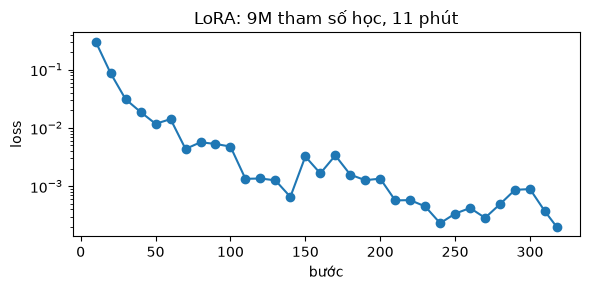

In [12]:
if RETRAIN or not (MERGED_DIR / "training_log.json").exists():
    history = lora_train.train_lora(HF_REPO, TRAIN_FILE, MERGED_DIR, **LORA)
else:
    history = json.load(open(MERGED_DIR / "training_log.json"))
    print("Đã có model dạy xong ở", MERGED_DIR, "(đặt RETRAIN = True để dạy lại)")

plt.figure(figsize=(6, 3))
plt.plot(history["step"], history["loss"], marker="o")
plt.yscale("log")
plt.xlabel("bước")
plt.ylabel("loss")
plt.title(f"LoRA: {history['trainable_params']/1e6:.0f}M tham số học, {history['seconds']//60} phút")
plt.tight_layout()
plt.show()

## 7. Đổi sang GGUF và nén

Bài dùng 4-bit nhóm 32 kèm huấn luyện nhận biết nén (QAT). Mình dùng **Q4_0**, cũng là 4-bit chia nhóm 32 trọng số, nhưng nén **sau** khi dạy
(không QAT). Thêm Q8_0 để biết nén nhẹ có đủ không.

In [13]:
gguf_paths = gguf_tools.export_gguf(MERGED_DIR, GGUF_DIR, "Qwen2.5-0.5B-toolB", QUANTS, LLAMA_DIR)
pd.DataFrame({"mức nén": list(gguf_paths), "dung lượng (MB)": [round(p.stat().st_size / 2**20, 1) for p in gguf_paths.values()]})

,mức nén,dung lượng (MB)
0,F16,948.1
1,Q8_0,506.5
2,Q4_0,335.8


## 8. Đo: có và không có bộ chọn công cụ

Bài so sánh "không RAG" với "có RAG". Mình đo theo kiểu đó, tất cả trên **CPU**:

| Cấu hình | Prompt chứa |
|---|---|
| F16, đủ 11 công cụ | cả 11 công cụ (không dùng bộ chọn) |
| F16 + Tool RAG | chỉ các công cụ bộ chọn trả về |
| Q8_0 + Tool RAG, Q4_0 + Tool RAG | như trên, với model nén |

Khi dùng bộ chọn, bảng cộng thêm `retr_ms` và `retr_mb` vào thời gian và RAM tổng (`p50_tổng_lạ`, `ram_tổng_mb`).
Lưu ý prefix cache: với bộ chọn, phần đầu của prompt thay đổi theo tập công cụ nên cache dùng lại được ít hơn so với cách A.

In [14]:
def ft_variant(quant, use_rag):
    suffix = " + Tool RAG" if use_rag else " | đủ 11 công cụ"
    label = f"B {quant}{suffix}"
    return label, E.ft_cfg(base_cfg, str(gguf_paths[quant]), label), (select_for if use_rag else None)


items = [ft_variant("F16", False), ft_variant("F16", True), ft_variant("Q8_0", True), ft_variant("Q4_0", True)]
variants = {label: (cfg, tools_for) for label, cfg, tools_for in items}

table = pd.concat([pd.DataFrame([baseline]), E.sweep(items, EVAL_SETS, gpu_layers=0)], ignore_index=True)
uses_rag = table["model"].str.contains("Tool RAG")
table["retr_ms"] = [retriever_ms if flag else 0 for flag in uses_rag]
table["retr_mb"] = [retriever_mb if flag else 0 for flag in uses_rag]
table["p50_tổng_lạ"] = (table["p50_lạ"] + table["retr_ms"] / 1000).round(2)
table["ram_tổng_mb"] = (table["ram_mb"] + table["retr_mb"]).round(1)
table

đang đo: B F16 | đủ 11 công cụ
đang đo: B F16 + Tool RAG
đang đo: B Q8_0 + Tool RAG
đang đo: B Q4_0 + Tool RAG


,model,file_mb,ok_156,over_156,p50_156,p95_156,ok_lạ,over_lạ,p50_lạ,p95_lạ,ram_mb,retr_ms,retr_mb,p50_tổng_lạ,ram_tổng_mb
0,Qwen gốc (F16),948.1,0.327,0.917,1.37,1.75,0.314,1.000,1.39,1.80,1075.5,0.00000,0.000000,1.39,1075.5
1,B F16 | đủ 11 công cụ,948.1,0.974,0.000,0.99,1.22,0.923,0.167,0.98,1.22,1046.5,0.00000,0.000000,0.98,1046.5
2,B F16 + Tool RAG,948.1,1.000,0.000,1.03,1.29,0.891,0.125,1.14,1.38,1046.4,27.19382,91.796875,1.17,1138.2
3,B Q8_0 + Tool RAG,506.5,1.000,0.000,0.72,0.93,0.891,0.125,0.86,1.03,604.4,27.19382,91.796875,0.89,696.2
4,B Q4_0 + Tool RAG,335.8,0.974,0.000,0.59,0.88,0.840,0.125,0.73,0.87,496.9,27.19382,91.796875,0.76,588.7


### Chọn cấu hình

Cùng quy tắc như cách A: lấy cấu hình có **RAM tổng nhỏ nhất** trong số những cấu hình có điểm trên bộ câu lạ không thấp hơn điểm tốt nhất quá 2 điểm phần trăm.

Cấu hình được chọn: B F16 | đủ 11 công cụ | RAM tổng 1046.5 MB, ok_156=0.974, ok_lạ=0.923, p50 tổng 0.98 s


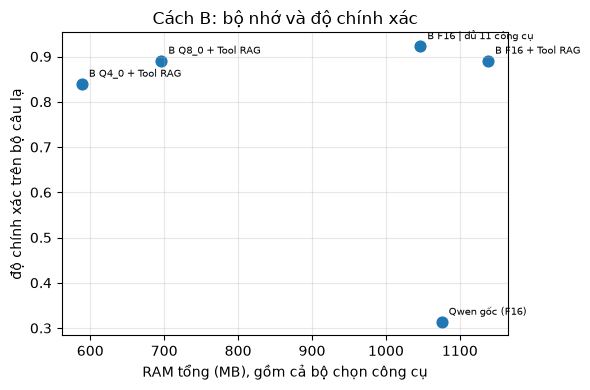

In [15]:
chosen = E.choose_smallest(table, prefix="B ", size_col="ram_tổng_mb")
print(f"Cấu hình được chọn: {chosen['model']} | RAM tổng {chosen['ram_tổng_mb']} MB, "
      f"ok_156={chosen['ok_156']}, ok_lạ={chosen['ok_lạ']}, p50 tổng {chosen['p50_tổng_lạ']} s")

plt.figure(figsize=(6, 4))
plt.scatter(table["ram_tổng_mb"], table["ok_lạ"], s=60)
for _, row in table.iterrows():
    plt.annotate(row["model"], (row["ram_tổng_mb"], row["ok_lạ"]), textcoords="offset points", xytext=(5, 5), fontsize=7)
plt.xlabel("RAM tổng (MB), gồm cả bộ chọn công cụ")
plt.ylabel("độ chính xác trên bộ câu lạ")
plt.title("Cách B: bộ nhớ và độ chính xác")
plt.grid(alpha=.3)
plt.tight_layout()
plt.show()

## 9. Model còn sai ở đâu

Phân tích lỗi trên bộ giữ riêng cho cấu hình đã chọn. Cột `model` là `None` nghĩa là model không gọi công cụ nào, `JSON_HONG` là JSON hỏng.
Nếu công cụ đúng không nằm trong tập mà bộ chọn trả về thì đó là **lỗi của bộ chọn**, không phải của Qwen.

In [16]:
chosen_cfg, chosen_tools_for = variants[chosen["model"]]
rows_held = E.evaluate(chosen_cfg, EVAL_SETS["lạ"], f"{chosen['model']} | câu lạ", tools_for=chosen_tools_for, gpu_layers=0)

errors = E.wrong_cases(rows_held, limit=20)
if chosen_tools_for:
    errors["bộ chọn đã giữ đúng công cụ"] = [c["tool"] is None or c["tool"] in chosen_tools_for(c)
                                             for c, _, s in rows_held if not s["ok"]][:len(errors)]
errors


== B F16 | đủ 11 công cụ | câu lạ (155s)
{'n': 156, 'ok': 0.923, 'tool_ok': 0.936, 'args_ok|tool_ok': 0.986, 'over_trigger': 0.167, 'tok_tb': 39.4, 'p50_s': 0.98, 'p95_s': 1.2}
nhầm tool (đúng -> model): 3x get_inspection_summary->get_production_stats, 3x None->request_line_stop, 1x None->request_line_restart, 1x get_live_telemetry->None, 1x trigger_audio_alarm->None, 1x get_live_telemetry->query_blackbox_logs


,câu,đúng,model,tham số đúng
0,hey i need braek in ten minutes,NaN,request_line_restart,{}
1,okay pull the latest live number for electrica...,get_live_telemetry,NaN,{'metric': 'current'}
2,give me the quality conrol numbers during toda...,get_inspection_summary,get_production_stats,{'period': 'today'}
3,um summon a person to examine the machine in p...,trigger_audio_alarm,NaN,{'alarm_code': 'ALERT_MANUAL_CHECK'}
4,scroll back through sixty minutes of conveyor ...,query_blackbox_logs,query_blackbox_logs,"{'target_metric': 'speed', 'lookback_minutes':..."
5,give me the quality control numbers across the...,get_inspection_summary,get_production_stats,{'period': 'last_hour'}
6,I need a break in ten minutes.,NaN,request_line_stop,{}
7,Pull the latest live number for motor heat.,get_live_telemetry,query_blackbox_logs,{'metric': 'temperature'}
8,um i need a break in ten minutes,NaN,request_line_stop,{}
9,uh give me quality control numbers in the most...,get_inspection_summary,get_production_stats,{'period': 'last_hour'}


## 10. Câu thật

Giống mục 9 của notebook A: dùng chung file `real_utterances.csv` (cột `text`, `tool`, `args`) do nhóm ghi lại.
Đây là phép thử công bằng nhất giữa hai cách, vì **cả hai bộ đo tự động đều dựng từ mẫu câu**, có thể thiên về cách A
(dữ liệu dạy của A cũng dựng từ mẫu câu cùng kiểu), trong khi cách B được dạy bằng câu do teacher viết, khác kiểu với bộ đo.

In [17]:
REAL_FILE = Path("real_utterances.csv")

if not REAL_FILE.exists():
    E.write_real_template(REAL_FILE)
else:
    real_cases = E.load_real(REAL_FILE)
    rows_real = E.evaluate(chosen_cfg, real_cases, f"{chosen['model']} | câu thật", tools_for=chosen_tools_for, gpu_layers=0)
    display(E.wrong_cases(rows_real, limit=30))


== B F16 | đủ 11 công cụ | câu thật (5s)
{'n': 3, 'ok': 1.0, 'tool_ok': 1.0, 'args_ok|tool_ok': 1.0, 'over_trigger': 0.0, 'tok_tb': 35.7, 'p50_s': 0.8, 'p95_s': 0.95}


""


## 11. So sánh với cách A và lưu kết quả

Nếu đã có `results/qwen05_A.json` thì bảng dưới đặt hai cách cạnh nhau (cấu hình được chọn của mỗi cách).

In [18]:
Path("results").mkdir(exist_ok=True)
summary = {
    "recipe": "B (theo TinyAgent)",
    "base": BASE_NAME,
    "teacher": TEACHER[0],
    "lora": LORA,
    "rag": RAG,
    "train_examples": history["examples"],
    "train_seconds": history["seconds"],
    "chosen": chosen["model"],
    "table": table.to_dict("records"),
}
json.dump(summary, open("results/qwen05_B.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
print("Đã lưu results/qwen05_B.json")

if result_A:
    a_table = pd.DataFrame(result_A["table"])
    a_table["ram_tổng_mb"] = a_table["ram_mb"]
    a_table["p50_tổng_lạ"] = a_table["p50_lạ"]
    a_row = a_table[a_table["model"] == "fine-tune " + result_A["chosen_quant"]].iloc[0].copy()
    a_row["model"] = "A: " + a_row["model"]
    columns = ["model", "file_mb", "ram_tổng_mb", "ok_156", "ok_lạ", "over_156", "over_lạ", "p50_tổng_lạ", "p95_lạ"]
    display(pd.DataFrame([a_row, chosen])[columns])
else:
    print("Chưa có kết quả của cách A để so sánh (chạy notebook A trước).")

Đã lưu results/qwen05_B.json


,model,file_mb,ram_tổng_mb,ok_156,ok_lạ,over_156,over_lạ,p50_tổng_lạ,p95_lạ
4,A: fine-tune Q4_K_M,379.4,484.3,1.000,0.968,0.0,0.167,0.57,0.83
1,B F16 | đủ 11 công cụ,948.1,1046.5,0.974,0.923,0.0,0.167,0.98,1.22


## Cách đọc kết quả

- **Điểm trên hai bộ đo tự động** có thể thiên về cách A, vì dữ liệu dạy của A và bộ đo cùng kiểu mẫu câu. Cách B được dạy bằng câu đa dạng hơn,
  nên mong đợi nó **khái quát tốt hơn với lời nói thật**. Chỉ phép đo trên câu thật (mục 10) mới trả lời được điều đó.
- **Bộ chọn công cụ** đổi một ít RAM và thời gian lấy prompt ngắn hơn. Với 11 công cụ, prompt đã được cache nên lợi ích có thể nhỏ.
  Xem cột `p50_tổng_lạ` và `ram_tổng_mb` để biết có đáng hay không. Bài gốc cần bộ chọn vì prompt dài hơn nhiều.
- **Không có QAT** ở bản này, nên Q4_0 có thể kém hơn so với bài. So sánh Q4_0 với F16 để biết mất bao nhiêu điểm.
- **Giới hạn:** teacher là Phi-4-mini nhỏ hơn GPT-4-Turbo của bài, nên chất lượng câu có thể kém hơn; RAM đo trên PC, chưa phải UNO Q.